In [44]:
#packages
## data manipulation
import pandas as pd
import numpy as np
## data viz
import seaborn as sns
import matplotlib.pyplot as plt
import json
import os

In [45]:
font_size_tics = 16
font_size_labels = 18

In [46]:
def create_default_folders():
    os.makedirs("plots", exist_ok=True)
    os.makedirs("results", exist_ok=True)

create_default_folders()

def get_experiment_definitions(scenario_name):
    f = open(f"{abspath}/experiment_definitions.json")
    data = json.load(f)
    definitions = data[scenario_name]    
    f.close()
    return definitions

In [47]:
# getting all results

## defining algo
import os
abspath = os.getcwd()
algo_list = ['carira', 'thea']
scenario_name = 'in-depth_analysis'

##LOAD SCENARIOS DEFINITIONS
dict_definitions = get_experiment_definitions(scenario_name)
scenario_list = dict_definitions['datasets']
seed_list = dict_definitions['seeds']

## experiment matrix schema
### object to save the final matrix
dt_exp_matrix = pd.DataFrame(columns=['Experiment', 'Algorithm', 'Workload', 'Cloud',
                                      'Latency SLA Violations_mean', 'Average Latency_mean', 'Drop SLA Violations_mean', 
                                      'Latency SLA Violations_std', 'Average Latency_std', 'Drop SLA Violations_std', 
                                      'Power Consumption_mean', 'Servers Usage_mean',
                                      'Power Consumption_std', 'Servers Usage_std'])
### object to save the total of experiments
dt_exp_matrix_total = pd.DataFrame(columns=['Experiment', 'Algorithm', 'Workload', 'Cloud', 
                                            'Latency SLA Violations', 'Average Latency', 'Drop SLA Violations', 'Average Latency SLA Violations',
                                            'Power Consumption', 'Servers Usage', 'Privacy Score', 'Availability Score', 'Drops'])
### object to count the quantity of experiments
n_exp = 0
# loop to get results
for algo_name in algo_list:

    for scenario in scenario_list:
        ## count experiment
        n_exp = n_exp + 1
        ## object to get results from all seeds
        dt_user_all_seeds = pd.DataFrame(columns=['Latency SLA Violations', 'Average Latency', 'Drop SLA Violations', 'Average Latency SLA Violations',])
        dt_server_all_seeds = pd.DataFrame(columns=['Power Consumption', 'Servers Usage'])
        dt_infra_all_seeds_privacy = pd.DataFrame(columns=['Privacy Score'])
        dt_infra_all_seeds_Availability = pd.DataFrame(columns=['Availability Score'])
        dt_infra_all_seeds_drops = pd.DataFrame(columns=['Drops'])
        ## print the experiment
        print(f"Exp.{n_exp}: {algo_name}_{scenario}")

        for seed_value in seed_list:
            
            ### getting results by seeds
            #### user
            dt_user_individual = pd.read_csv(f"results/{algo_name}_user_{scenario}_{seed_value}.csv")
            dt_user_individual_seed = pd.DataFrame(dt_user_individual.loc[:, ['Average Latency']].mean()).T
            dt_user_individual_seed['Drop SLA Violations'] = dt_user_individual.loc[:, 'Drop SLA Violations'].sum()
            dt_user_individual_seed['Latency SLA Violations'] = dt_user_individual.loc[:, 'Latency SLA Violations'].sum()
            dt_user_individual_seed['Average Latency SLA Violations'] = dt_user_individual.loc[:, 'Latency SLA Violations'].mean()
            dt_user_individual_seed = dt_user_individual_seed.loc[:, dt_user_all_seeds.columns]
            #### save results of all seeds for each experiment
            dt_user_all_seeds = pd.concat([dt_user_all_seeds, dt_user_individual_seed])
            #### server
            dt_server_individual = pd.read_csv(f"results/{algo_name}_server_{scenario}_{seed_value}.csv")
            dt_server_individual_seed = pd.DataFrame(dt_server_individual.loc[:, ['Servers Usage']].mean()).T
            dt_server_individual_seed['Power Consumption'] = dt_server_individual.loc[:, 'Power Consumption'].sum()
            dt_server_individual_seed = dt_server_individual_seed.loc[:, dt_server_all_seeds.columns]
            #### save results of all seeds for each experiment
            dt_server_all_seeds = pd.concat([dt_server_all_seeds, dt_server_individual_seed])
            
            #ADD APP PRIVACY SCORE
            dt_infra_privacy = pd.read_csv(f"results/{algo_name}_privacy_{scenario}_{seed_value}.csv")
            dt_infra_privacy_seed = pd.DataFrame(dt_infra_privacy.loc[:, ['Privacy Score']].mean()).T
            dt_infra_all_seeds_privacy = pd.concat([dt_infra_all_seeds_privacy, dt_infra_privacy_seed])

            #ADD APP Availability SCORE
            dt_infra_Availability = pd.read_csv(f"results/{algo_name}_Availability_{scenario}_{seed_value}.csv")
            dt_infra_Availability_seed = pd.DataFrame(dt_infra_Availability.loc[:, ['Availability Score']].mean()).T
            dt_infra_all_seeds_Availability = pd.concat([dt_infra_all_seeds_Availability, dt_infra_Availability_seed])

            #ADD APP Drops SCORE
            dt_infra_drops = pd.read_csv(f"results/{algo_name}_drops_{scenario}_{seed_value}.csv")
            dt_infra_drops_seed = pd.DataFrame(dt_infra_drops.loc[:, ['Drops']].sum()).T
            dt_infra_all_seeds_drops = pd.concat([dt_infra_all_seeds_drops, dt_infra_drops_seed])

        dt_all_seeds = pd.concat([dt_user_all_seeds.reset_index(drop=True),dt_server_all_seeds.reset_index(drop=True), dt_infra_all_seeds_privacy.reset_index(drop=True),dt_infra_all_seeds_Availability.reset_index(drop=True),dt_infra_all_seeds_drops.reset_index(drop=True)], axis=1)
    

        ## save all experiments results
        dt_all_seeds_total = dt_all_seeds.reset_index(drop=True)
        dt_all_seeds_total['Experiment'] = n_exp
        dt_all_seeds_total['Algorithm'] = algo_name
        dt_all_seeds_total['Workload'] = scenario.split('_')[1]
        dt_all_seeds_total['Cloud'] = scenario.split('_')[2]
        
        dt_all_seeds_total = dt_all_seeds_total.loc[:, dt_exp_matrix_total.columns]
        ### final object to save all experiments
        dt_exp_matrix_total = pd.concat([dt_exp_matrix_total, dt_all_seeds_total], axis=0).reset_index(drop=True)

        
        
        ## with the avg and std values create experiment matrix
        ### mean values
        mean_columns_name = pd.DataFrame(dt_all_seeds.mean()).T.columns + '_mean'        
        dt_seeds_mean = pd.DataFrame(dt_all_seeds.mean()).T
        dt_seeds_mean.columns = mean_columns_name
        ### std values
        std_columns_name = pd.DataFrame(dt_all_seeds.std()).T.columns + '_std'        
        dt_seeds_std = pd.DataFrame(dt_all_seeds.std()).T
        dt_seeds_std.columns = std_columns_name
        ### concat mean and std results
        dt_seeds_mean_std = pd.concat([dt_seeds_mean, dt_seeds_std], axis=1)
        dt_seeds_mean_std['Experiment'] = n_exp
        dt_seeds_mean_std['Algorithm'] = algo_name
        dt_seeds_mean_std['Workload'] = scenario.split('_')[1]
        dt_seeds_mean_std['Cloud'] = scenario.split('_')[2]
        ### final object to save the exp matrix
        dt_exp_matrix = pd.concat([dt_exp_matrix, dt_seeds_mean_std], axis=0).reset_index(drop=True)
display(dt_exp_matrix)

Exp.1: carira_1pla_low_on
Exp.2: carira_1pla_low_off
Exp.3: carira_1pla_high_on
Exp.4: carira_1pla_high_off
Exp.5: thea_1pla_low_on
Exp.6: thea_1pla_low_off
Exp.7: thea_1pla_high_on
Exp.8: thea_1pla_high_off


,Experiment,Algorithm,Workload,Cloud,Latency SLA Violations_mean,Average Latency_mean,Drop SLA Violations_mean,Latency SLA Violations_std,Average Latency_std,Drop SLA Violations_std,...,Power Consumption_std,Servers Usage_std,Average Latency SLA Violations_mean,Privacy Score_mean,Availability Score_mean,Drops_mean,Average Latency SLA Violations_std,Privacy Score_std,Availability Score_std,Drops_std
0,1,carira,low,on,0.9,15.876,0.0,0.875595,0.953767,0.0,...,0.0,0.0,0.18,0.1,0.683333,0.0,0.175119,0.0,0.0,0.0
1,2,carira,low,off,0.0,15.228,0.0,0.0,0.357299,0.0,...,0.0,0.0,0.0,0.1,0.683333,0.0,0.0,0.0,0.0,0.0
2,3,carira,high,on,17.1,20.802,0.0,1.72884,1.042068,0.0,...,0.0,0.0,1.71,0.294444,0.583333,0.0,0.172884,0.0,0.0,0.0
3,4,carira,high,off,0.0,12.134,0.0,0.0,0.195061,0.0,...,0.0,0.0,0.0,-0.105556,0.55,12.0,0.0,0.0,0.0,0.0
4,5,thea,low,on,0.9,11.536,0.0,0.875595,0.959667,0.0,...,0.0,0.0,0.18,0.4,0.35,0.0,0.175119,0.0,0.0,0.0
5,6,thea,low,off,0.0,8.788,0.0,0.0,0.360765,0.0,...,0.0,0.0,0.0,0.4,0.35,0.0,0.0,0.0,0.0,0.0
6,7,thea,high,on,32.6,26.474,0.0,1.264911,0.744285,0.0,...,0.0,0.0,3.26,0.527778,0.341667,0.0,0.126491,0.0,0.0,0.0
7,8,thea,high,off,0.0,8.466,0.0,0.0,0.259752,0.0,...,0.0,0.0,0.0,-0.011111,0.266667,13.0,0.0,0.0,0.0,0.0


In [48]:
# check the data type
numeric_columns = ['Latency SLA Violations', 'Average Latency', 'Drop SLA Violations',
                   'Power Consumption', 'Servers Usage']
for column in numeric_columns:
    dt_exp_matrix_total[column] = dt_exp_matrix_total[column].astype(np.float64).round(decimals=2)

numeric_columns = ['Latency SLA Violations_mean', 'Average Latency_mean', 'Drop SLA Violations_mean', 
                   'Power Consumption_mean', 'Servers Usage_mean',
                   'Latency SLA Violations_std', 'Average Latency_std', 'Drop SLA Violations_std',
                   'Power Consumption_std', 'Servers Usage_std']
for column in numeric_columns:
    dt_exp_matrix[column] = dt_exp_matrix[column].astype(np.float64).round(decimals=2)

# remove some columns
table_to_paper = dt_exp_matrix#.drop(columns=['Delays slas usage_mean', 'Delays slas usage_std'])
# save table
table_to_paper.to_csv('table_to_paper.csv', index=False)
table_to_paper.to_excel('table_to_paper.xlsx', index=False)
table_to_paper.loc[:, ['Latency SLA Violations_mean', 'Drop SLA Violations_mean', 'Average Latency_mean', 'Power Consumption_mean', 'Servers Usage_mean']].to_csv('data_for_plots.csv', index=False)
display(table_to_paper, dt_exp_matrix_total)

,Experiment,Algorithm,Workload,Cloud,Latency SLA Violations_mean,Average Latency_mean,Drop SLA Violations_mean,Latency SLA Violations_std,Average Latency_std,Drop SLA Violations_std,...,Power Consumption_std,Servers Usage_std,Average Latency SLA Violations_mean,Privacy Score_mean,Availability Score_mean,Drops_mean,Average Latency SLA Violations_std,Privacy Score_std,Availability Score_std,Drops_std
0,1,carira,low,on,0.9,15.88,0.0,0.88,0.95,0.0,...,0.0,0.0,0.18,0.1,0.683333,0.0,0.175119,0.0,0.0,0.0
1,2,carira,low,off,0.0,15.23,0.0,0.00,0.36,0.0,...,0.0,0.0,0.0,0.1,0.683333,0.0,0.0,0.0,0.0,0.0
2,3,carira,high,on,17.1,20.80,0.0,1.73,1.04,0.0,...,0.0,0.0,1.71,0.294444,0.583333,0.0,0.172884,0.0,0.0,0.0
3,4,carira,high,off,0.0,12.13,0.0,0.00,0.20,0.0,...,0.0,0.0,0.0,-0.105556,0.55,12.0,0.0,0.0,0.0,0.0
4,5,thea,low,on,0.9,11.54,0.0,0.88,0.96,0.0,...,0.0,0.0,0.18,0.4,0.35,0.0,0.175119,0.0,0.0,0.0
5,6,thea,low,off,0.0,8.79,0.0,0.00,0.36,0.0,...,0.0,0.0,0.0,0.4,0.35,0.0,0.0,0.0,0.0,0.0
6,7,thea,high,on,32.6,26.47,0.0,1.26,0.74,0.0,...,0.0,0.0,3.26,0.527778,0.341667,0.0,0.126491,0.0,0.0,0.0
7,8,thea,high,off,0.0,8.47,0.0,0.00,0.26,0.0,...,0.0,0.0,0.0,-0.011111,0.266667,13.0,0.0,0.0,0.0,0.0


,Experiment,Algorithm,Workload,Cloud,Latency SLA Violations,Average Latency,Drop SLA Violations,Average Latency SLA Violations,Power Consumption,Servers Usage,Privacy Score,Availability Score,Drops
0,1,carira,low,on,0.0,14.72,0.0,0.0,616.5,58.08,0.1,0.683333,0
1,1,carira,low,on,0.0,15.48,0.0,0.0,616.5,58.08,0.1,0.683333,0
2,1,carira,low,on,0.0,14.64,0.0,0.0,616.5,58.08,0.1,0.683333,0
3,1,carira,low,on,2.0,16.60,0.0,0.4,616.5,58.08,0.1,0.683333,0
4,1,carira,low,on,2.0,17.56,0.0,0.4,616.5,58.08,0.1,0.683333,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,8,thea,high,off,0.0,8.70,0.0,0.0,808.0,90.91,-0.011111,0.266667,13
76,8,thea,high,off,0.0,8.78,0.0,0.0,808.0,90.91,-0.011111,0.266667,13
77,8,thea,high,off,0.0,8.40,0.0,0.0,808.0,90.91,-0.011111,0.266667,13
78,8,thea,high,off,0.0,8.62,0.0,0.0,808.0,90.91,-0.011111,0.266667,13


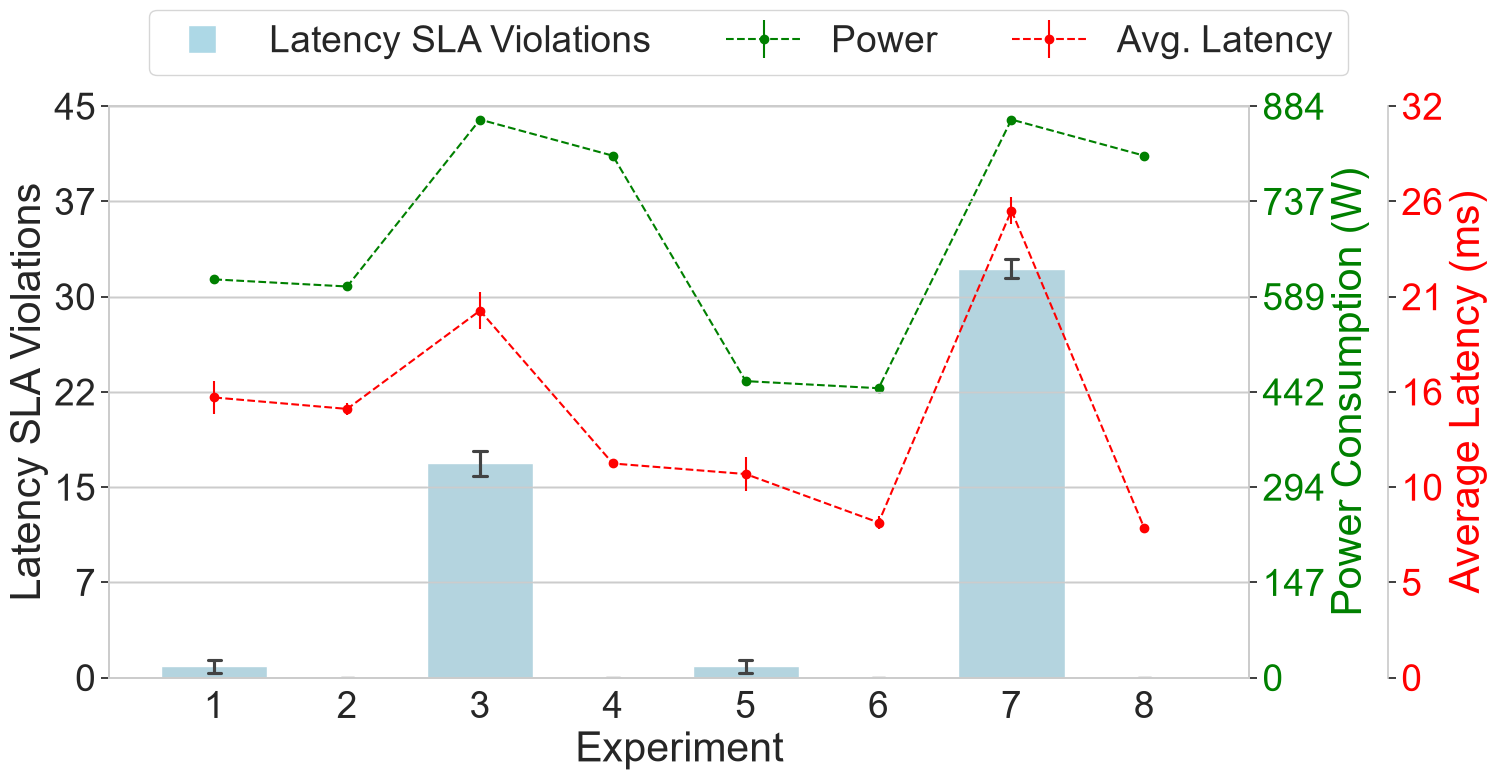

In [49]:
# list of response variables
y_list = ['Latency SLA Violations']#, 'Drop SLA Violations', 'Average Latency', 'Power Consumption', 'Servers Usage']
y_list_with_units = ['Latency SLA Violations', 'Drop SLA Violations', 'Average Latency (ms)', 'Power Consumption (W)', 'Servers Usage (%)']

# Bar plot by experiment
for i in range(len(y_list)):
    
    y_name = y_list[i]

    ## Set the figure size
    sns.set(style="whitegrid", font_scale=2.45)
    fig, ax1 = plt.subplots(figsize=(16, 8))

    ## plot a bar chart
    sns.barplot(x="Experiment", y=y_name, data=dt_exp_matrix_total, 
                    estimator=np.mean, errorbar=('ci', 95), capsize=.1, 
                    color='lightblue', width=0.8, ax=ax1)
    ## set x label    
    
    # ax1.set_xticks(range(len(dt_exp_matrix)), labels=['Ep.1\n' + algo_list[0] + '\nlow\non', 'Ep.2\n' + algo_list[0] + '\nlow\noff', 
    #                                                 'Ep.3\n' + algo_list[0] + '\nhigh\non', 'Ep.4\n' + algo_list[0] + '\nhigh\noff',
    #                                                 'Ep.5\n' + algo_list[1] + '\nlow\non', 'Ep.6\n' + algo_list[1] + '\nlow\noff', 
    #                                                 'Ep.7\n' + algo_list[1] + '\nhigh\non', 'Ep.8\n' + algo_list[1] + '\nhigh\noff',
    #                                                 'Ep.5\n' + algo_list[2] + '\nlow\non', 'Ep.6\n' + algo_list[2] + '\nlow\noff', 
    #                                                 'Ep.7\n' + algo_list[2] + '\nhigh\non', 'Ep.8\n' + algo_list[2] + '\nhigh\noff',
    #                                                 'Ep.5\n' + algo_list[3] + '\nlow\non', 'Ep.6\n' + algo_list[3] + '\nlow\noff', 
    #                                                 'Ep.7\n' + algo_list[3] + '\nhigh\non', 'Ep.8\n' + algo_list[3] + '\nhigh\noff',
    #                                                 'Ep.5\n' + algo_list[4] + '\nlow\non', 'Ep.6\n' + algo_list[4] + '\nlow\noff', 
    #                                                 'Ep.7\n' + algo_list[4] + '\nhigh\non', 'Ep.8\n' + algo_list[4] + '\nhigh\noff'])
    
    ax1.set_ylabel("Latency SLA Violations")

    ## Create second y-axis for "Power Consumption"
    ax2 = ax1.twinx()
    ax2.set_ylabel('Power Consumption (W)', color='green')

    ## Plot the green "Power Consumption" line using mean values
    #power_means = dt_exp_matrix_total.groupby('Experiment')['Power Consumption'].mean()
    #ax2.plot((power_means.index - 1), power_means.values, 
    #         color='green', linestyle='--', marker='o', label="Power Consumption")
    #ax2.tick_params(axis='y', labelcolor='green')

    ## Plot the green "Power Consumption" line with standard deviation error bars
    power_means = dt_exp_matrix_total.groupby('Experiment')['Power Consumption'].mean()
    power_std = dt_exp_matrix_total.groupby('Experiment')['Power Consumption'].std()  # Add standard deviation column here
    ax2.errorbar((power_means.index - 1), power_means.values, 
                 yerr=power_std.values, fmt='--o', color='green', label="Power", capsize=0)
    ax2.tick_params(axis='y', labelcolor='green')

    ## Create third y-axis for "Average Latency"
    ax3 = ax1.twinx()
    ax3.spines.right.set_position(("outward", 100))  # Increased to 100 for more space
    ax3.set_ylabel('Average Latency (ms)', color='red')

    ## Plot the red "Average Latency" line using mean values
    #latency_means = dt_exp_matrix_total.groupby('Experiment')['Average Latency'].mean()
    #ax3.plot((latency_means.index - 1), latency_means.values, 
    #         color='red', linestyle='--', marker='o', label="Average Latency")
    #ax3.tick_params(axis='y', labelcolor='red')

    latency_means = dt_exp_matrix_total.groupby('Experiment')['Average Latency'].mean()
    latency_std = dt_exp_matrix_total.groupby('Experiment')['Average Latency'].std()  # Add standard deviation column here
    ax3.errorbar((latency_means.index - 1), latency_means.values, 
                 yerr=latency_std.values, fmt='--o', color='red', label="Avg. Latency", capsize=0)
    ax3.tick_params(axis='y', labelcolor='red')

    ## Set the same number of ticks for all axes
    n_ticks = 7   # Define the desired number of ticks

    # Set the y-axis limits to start from zero
    ax1.set_ylim(0, ax1.get_ylim()[1]*1.3)
    ax2.set_ylim(0, ax2.get_ylim()[1]*1)
    ax3.set_ylim(0, ax3.get_ylim()[1]*1.15)
    
    # Get the limits for each y-axis
    ax1_lim = ax1.get_ylim()
    ax2_lim = ax2.get_ylim()
    ax3_lim = ax3.get_ylim()
    
    # Set evenly spaced ticks for all y-axes
    ax1.set_yticks(np.linspace(ax1_lim[0], ax1_lim[1], n_ticks))
    ax2.set_yticks(np.linspace(ax2_lim[0], ax2_lim[1], n_ticks))
    ax3.set_yticks(np.linspace(ax3_lim[0], ax3_lim[1], n_ticks))

    ## Round the tick values and remove decimals
    ax1.set_yticklabels([f'{int(tick)}' for tick in ax1.get_yticks()])
    ax2.set_yticklabels([f'{int(tick)}' for tick in ax2.get_yticks()])
    ax3.set_yticklabels([f'{int(tick)}' for tick in ax3.get_yticks()])

     ## Create legends for all axes
    handles2, labels2 = ax2.get_legend_handles_labels()  # Get handles and labels from ax2
    handles3, labels3 = ax3.get_legend_handles_labels()  # Get handles and labels from ax3

    # Manually create a handle for the bar plot in ax1
    bar_handle = plt.Line2D([0], [0], marker='s', color='w', label='Latency SLA Violations', 
                             markerfacecolor='lightblue', markersize=20)
    
    # Combine all handles and labels
    handles = [bar_handle] + handles2 + handles3
    labels = ['Latency SLA Violations'] + labels2 + labels3

    # Add legend above the plot
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=3)  # Adjust ncol as needed

    # Adjust layout to provide space for the legend
    plt.tight_layout(pad=1.5)  # Increase padding                        for better spacing
                    
    # Save the figures ensuring everything fits
    plt.savefig(f"plots/allalgo_exp_by_{y_name}_complete.png", dpi=300, bbox_inches='tight')
    plt.savefig(f"plots/allalgo_exp_by_{y_name}_complete.pdf", format='pdf', bbox_inches='tight')
    plt.show() 

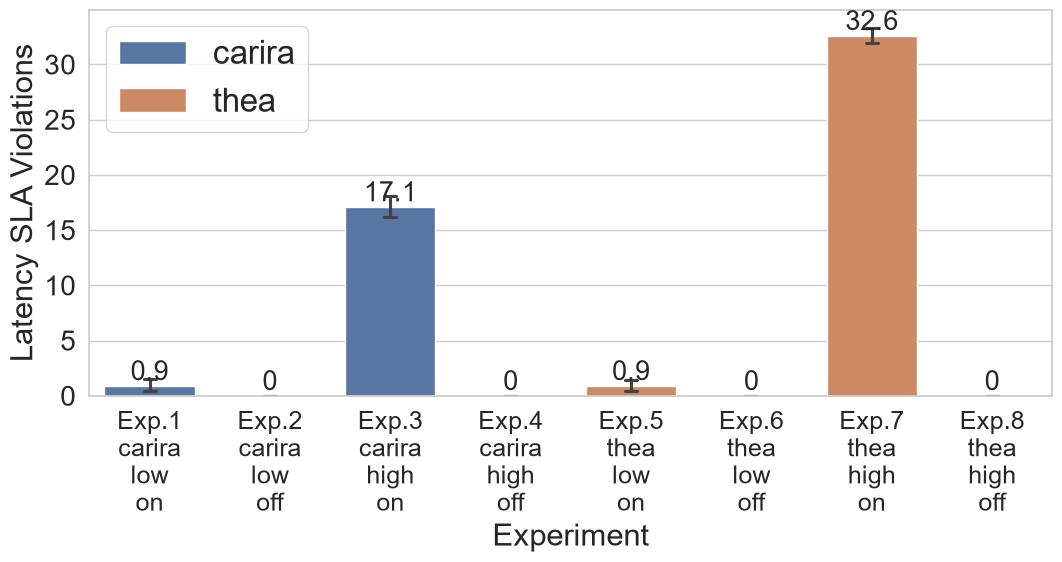

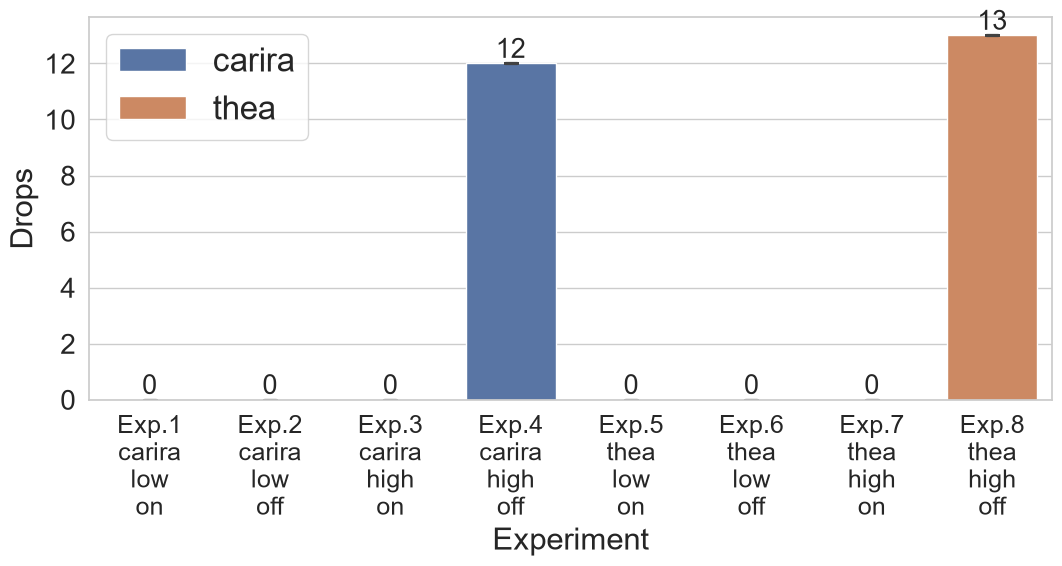

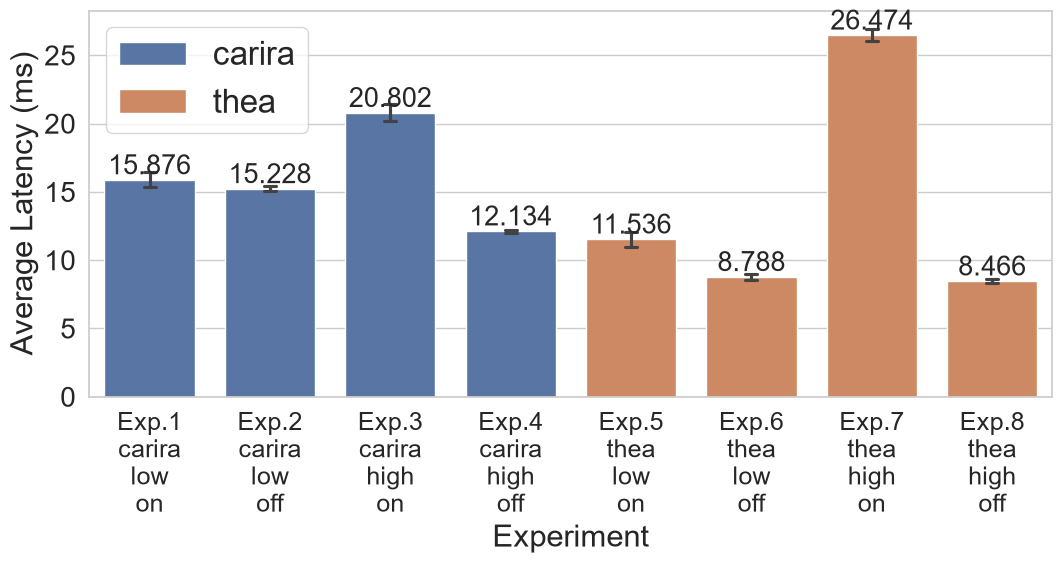

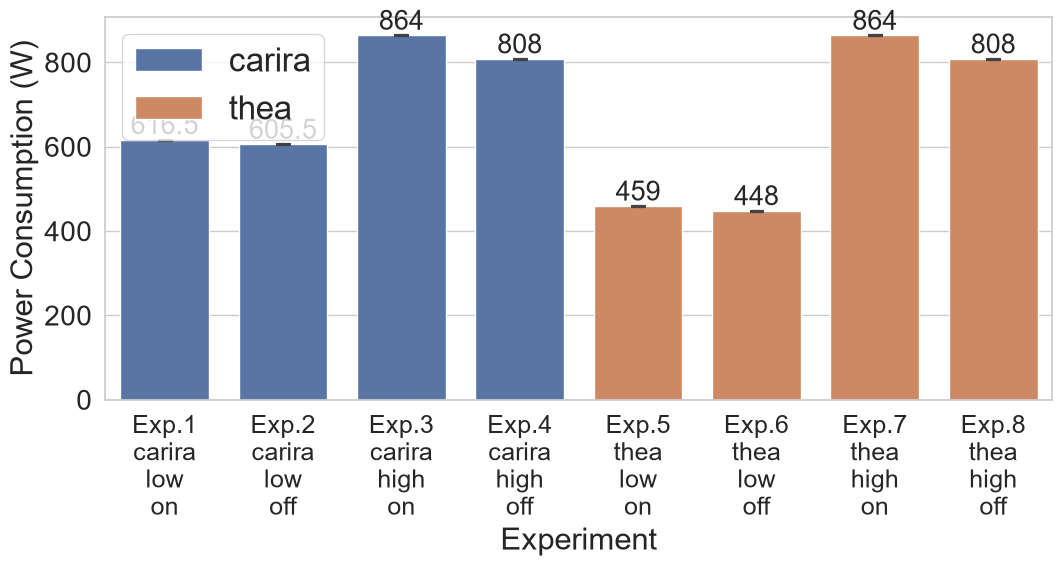

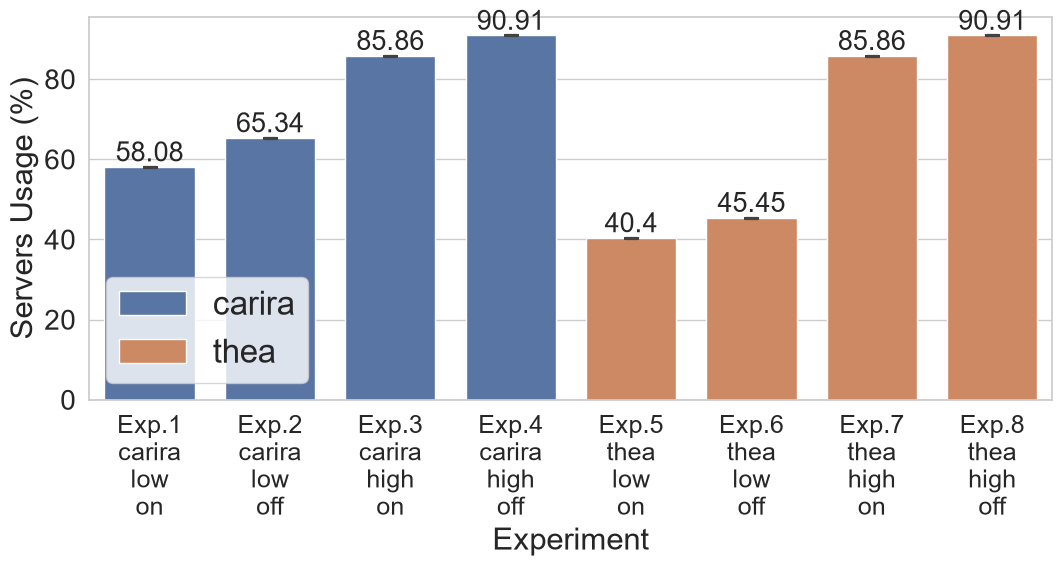

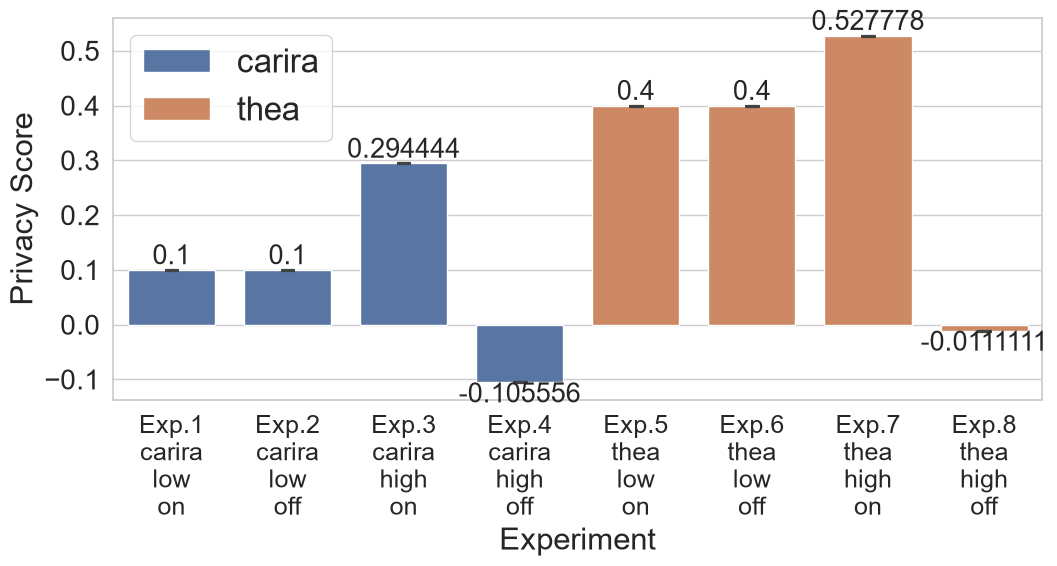

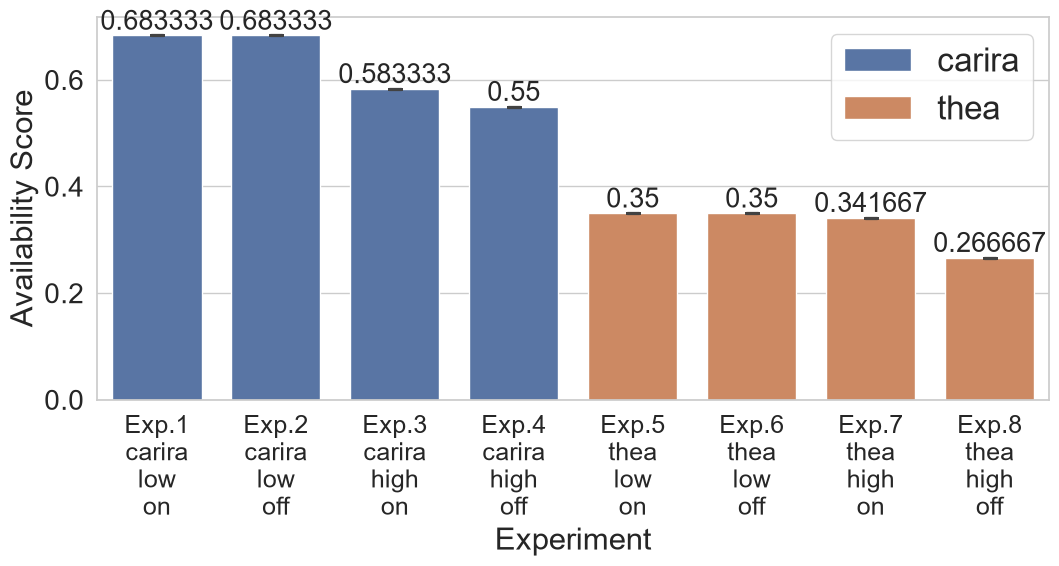

In [50]:
# list of response variables
y_list = ['Latency SLA Violations', 'Drops', 'Average Latency', 'Power Consumption', 'Servers Usage', 'Privacy Score', 'Availability Score']
y_list_with_units = ['Latency SLA Violations', 'Drops', 'Average Latency (ms)', 'Power Consumption (W)', 'Servers Usage (%)', 'Privacy Score (0-1)', 'Availability Score (0-1)']
# Bar plot by experiment
for i in range(len(y_list)):
    y_name = y_list[i]
    ## Set the figure size
    sns.set(style="whitegrid", font_scale=1.6)
    plt.figure(figsize=(11, 6))
    ## plot a bar chart
    ax = sns.barplot(x="Experiment", y=y_name, data=dt_exp_matrix_total, 
                    estimator=np.mean, errorbar=('ci', 95), capsize=.1, 
                    width=0.75, hue='Algorithm')
    ## set x label

    ax.set_xticks(range(len(dt_exp_matrix)), labels=['Exp.1\n' + algo_list[0] + '\nlow\non', 'Exp.2\n' + algo_list[0] + '\nlow\noff',
                                                     'Exp.3\n' + algo_list[0] + '\nhigh\non', 'Exp.4\n' + algo_list[0] + '\nhigh\noff',
                                                     'Exp.5\n' + algo_list[1] + '\nlow\non', 'Exp.6\n' + algo_list[1] + '\nlow\noff',
                                                     'Exp.7\n' + algo_list[1] + '\nhigh\non', 'Exp.8\n' + algo_list[1] + '\nhigh\noff',])
    
    if y_name in ['Average Latency', 'Power Consumption', 'Servers Usage']:
            y_name = y_list_with_units[i]
            ax.set(ylabel=y_name)

    plt.legend(fontsize=24)
    plt.yticks(fontsize=font_size_tics + 4)
    plt.xticks(fontsize=font_size_tics + 2)
    plt.ylabel(y_name, fontsize=font_size_labels + 4)
    plt.xlabel('Experiment', fontsize=font_size_labels + 4)
    ax.bar_label(ax.containers[0])
    ax.bar_label(ax.containers[1])
    plt.tight_layout()
    plt.savefig(f"plots/allalgo_exp_by_{y_name}.png", dpi=300)
    plt.savefig(f"plots/allalgo_exp_by_{y_name}.pdf", format='pdf')
    plt.show()

In [51]:
print(dt_exp_matrix_total.head())

  Experiment Algorithm Workload Cloud  Latency SLA Violations  \
0          1    carira      low    on                     0.0   
1          1    carira      low    on                     0.0   
2          1    carira      low    on                     0.0   
3          1    carira      low    on                     2.0   
4          1    carira      low    on                     2.0   

   Average Latency  Drop SLA Violations Average Latency SLA Violations  \
0            14.72                  0.0                            0.0   
1            15.48                  0.0                            0.0   
2            14.64                  0.0                            0.0   
3            16.60                  0.0                            0.4   
4            17.56                  0.0                            0.4   

   Power Consumption  Servers Usage Privacy Score Availability Score Drops  
0              616.5          58.08           0.1           0.683333     0  
1         

In [52]:
algo_final_mean = dt_exp_matrix_total[['Algorithm', 'Latency SLA Violations', 'Drops', 'Average Latency', 'Power Consumption', 'Availability Score', 'Servers Usage']].groupby(by='Algorithm').mean().round(decimals=2).reset_index()
algo_final_sd = dt_exp_matrix_total[['Algorithm', 'Latency SLA Violations', 'Drops', 'Average Latency', 'Power Consumption', 'Availability Score', 'Servers Usage']].groupby(by='Algorithm').std().round(decimals=2).reset_index()
#display(algo_final_mean, algo_final_sd)

cloud_final_mean = dt_exp_matrix_total[['Cloud', 'Latency SLA Violations', 'Drops', 'Average Latency', 'Power Consumption', 'Availability Score', 'Servers Usage']].groupby(by='Cloud').mean().round(decimals=2).reset_index()
cloud_final_sd = dt_exp_matrix_total[['Cloud', 'Latency SLA Violations',   'Drops', 'Average Latency', 'Power Consumption', 'Availability Score', 'Servers Usage']].groupby(by='Cloud').std().round(decimals=2).reset_index()
workload_final_mean = dt_exp_matrix_total[['Workload', 'Latency SLA Violations', 'Drops', 'Average Latency', 'Power Consumption', 'Availability Score', 'Servers Usage']].groupby(by='Workload').mean().round(decimals=2).reset_index()
workload_final_sd = dt_exp_matrix_total[['Workload', 'Latency SLA Violations', 'Drops', 'Average Latency', 'Power Consumption', 'Availability Score', 'Servers Usage']].groupby(by='Workload').std().round(decimals=2).reset_index()

print("############### ALGORITMO #######################")
display(algo_final_mean)
print("SD")
display(algo_final_sd)

print("############### CLOUD #######################")
display(cloud_final_mean)
print("SD")
display(cloud_final_sd)

print("############### WORKLOAD #######################")
display(workload_final_mean)
print("SD")
display(workload_final_sd)


############### ALGORITMO #######################


,Algorithm,Latency SLA Violations,Drops,Average Latency,Power Consumption,Availability Score,Servers Usage
0,carira,4.50,3.0,16.01,723.50,0.625,75.05
1,thea,8.38,3.25,13.82,644.75,0.327083,65.65


SD


,Algorithm,Latency SLA Violations,Drops,Average Latency,Power Consumption,Availability Score,Servers Usage
0,carira,7.44,5.26,3.22,115.75,0.06,13.87
1,thea,14.19,5.70,7.52,194.76,0.04,23.16


############### CLOUD #######################


...

,Cloud,Latency SLA Violations,Drops,Average Latency,Power Consumption,Availability Score,Servers Usage
0,off,0.00,6.34,2.81,153.18,0.17,19.34
1,on,13.39,0.00,5.71,174.56,0.15,19.59


############### WORKLOAD #######################


,Workload,Latency SLA Violations,Drops,Average Latency,Power Consumption,Availability Score,Servers Usage
0,high,12.42,6.25,16.97,836.00,0.435417,88.38
1,low,0.45,0.0,12.86,532.25,0.516667,52.32


SD


,Workload,Latency SLA Violations,Drops,Average Latency,Power Consumption,Availability Score,Servers Usage
0,high,13.79,6.34,7.20,28.36,0.14,2.56
1,low,0.75,0.00,2.99,79.95,0.17,10.03


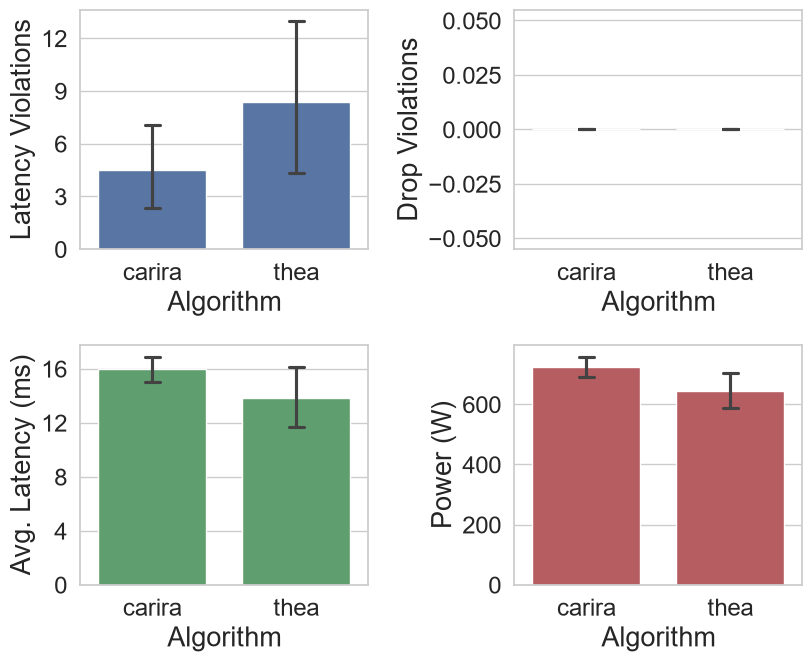

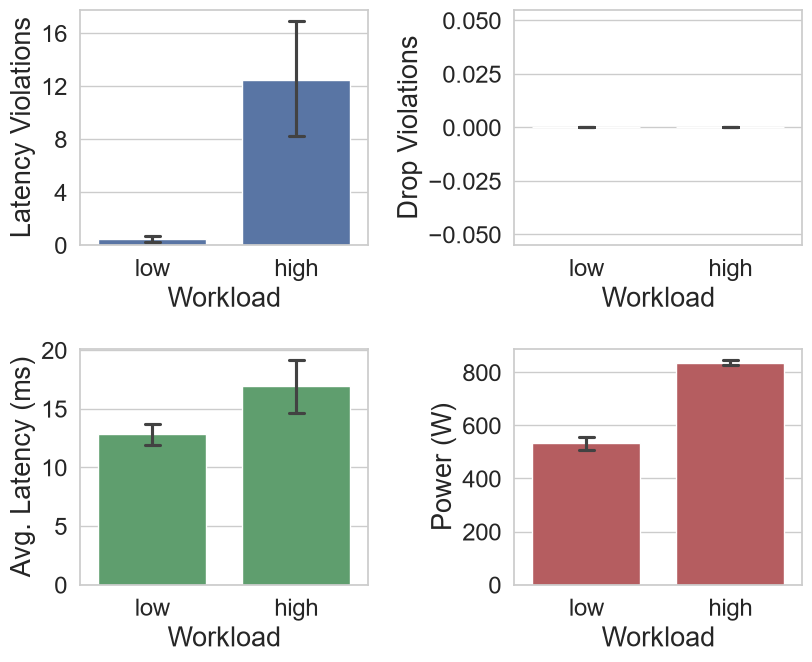

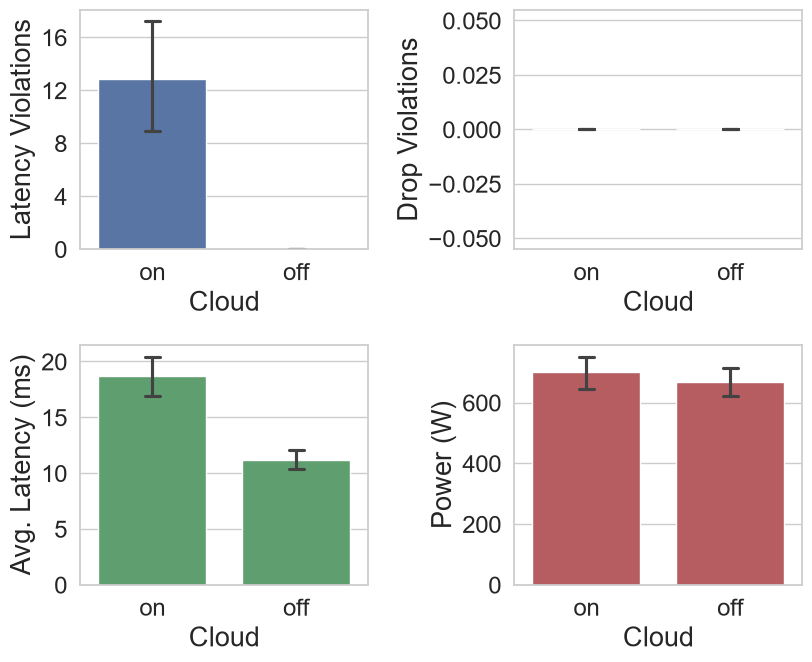

In [53]:
from matplotlib.ticker import MaxNLocator
# list of response variables
y_list = ['Latency SLA Violations', 'Drop SLA Violations', 'Average Latency', 'Power Consumption']
y_list_with_units = ['Latency Violations', 'Drop Violations', 'Avg. Latency (ms)', 'Power (W)']

# Bar plot by factor
# Defining a color list for the response variables
colors = ['cyan', 'skyblue', 'salmon', 'lightgreen', 'violet', 'gold', 'violet', 'lightgrey', 'orange', 'cyan']

# loop to get all factors
factor_list = ['Algorithm', 'Workload', 'Cloud']
for factor_name in factor_list:
    # Set the figure size
    sns.set(style="whitegrid", font_scale=1.6)
    fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(8.5, 7))  # Adjusted for 2x2 layout
    
    # Flatten the axs array for easy iteration
    axs = axs.flatten()
    
    # loop to create plots
    for i in range(len(y_list)):
        y_name = y_list[i]
        sns.barplot(x=factor_name, y=y_name, data=dt_exp_matrix_total, 
                    estimator=np.mean, errorbar=('ci', 95), capsize=.1, 
                    color=sns.color_palette()[i], width=0.75, ax=axs[i])
        
        if y_name in ['Latency SLA Violations', 'Drop SLA Violations', 'Average Latency', 'Power Consumption']:
            y_name = y_list_with_units[i]
            axs[i].set(ylabel=y_name)

        # Control the number of y-axis ticks
        axs[i].yaxis.set_major_locator(MaxNLocator(nbins=5))  # Adjust nbins as needed

    plt.tight_layout()
    plt.savefig(f"plots/allalgo_{factor_name}_by_reponsevars_2x2.png", dpi=300)
    plt.savefig(f"plots/allalgo_{factor_name}_by_reponsevars_2x2.pdf", format='pdf')
    plt.show()

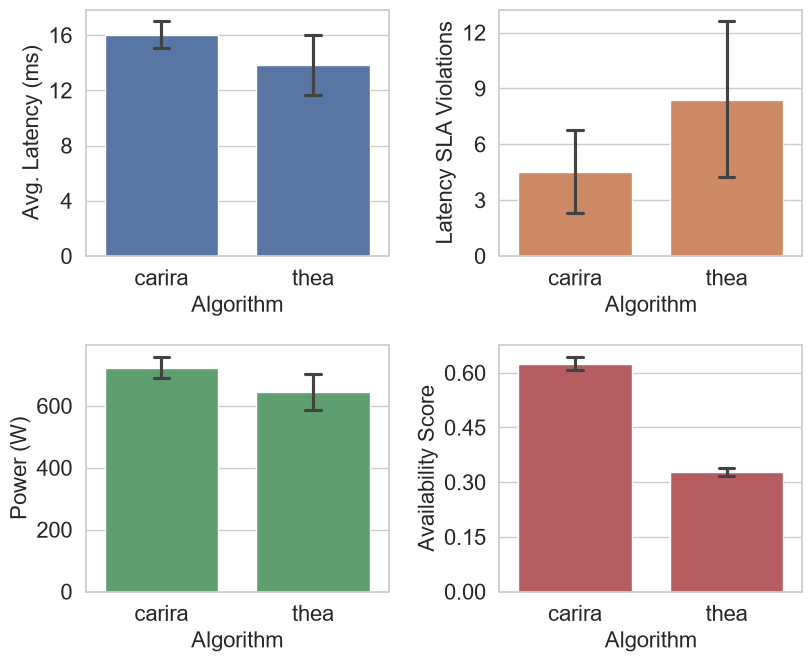

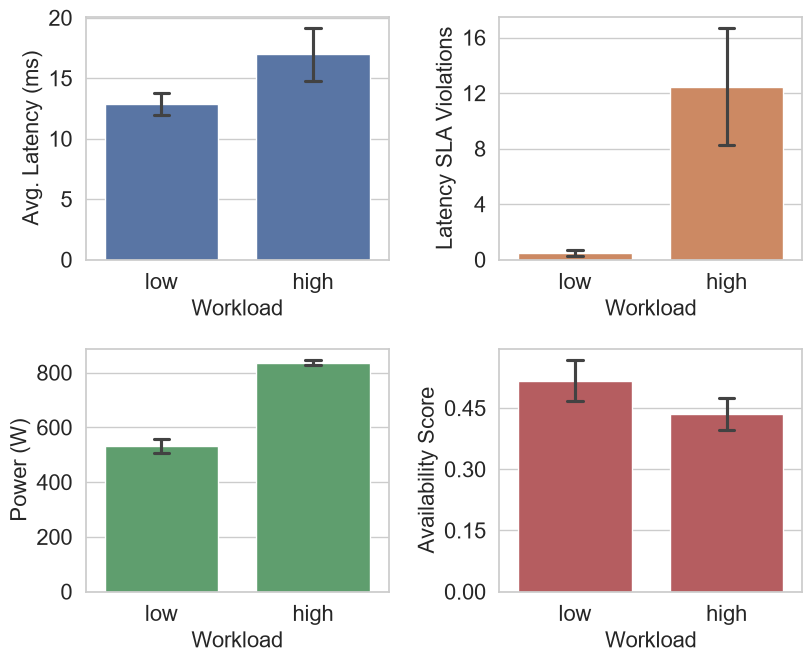

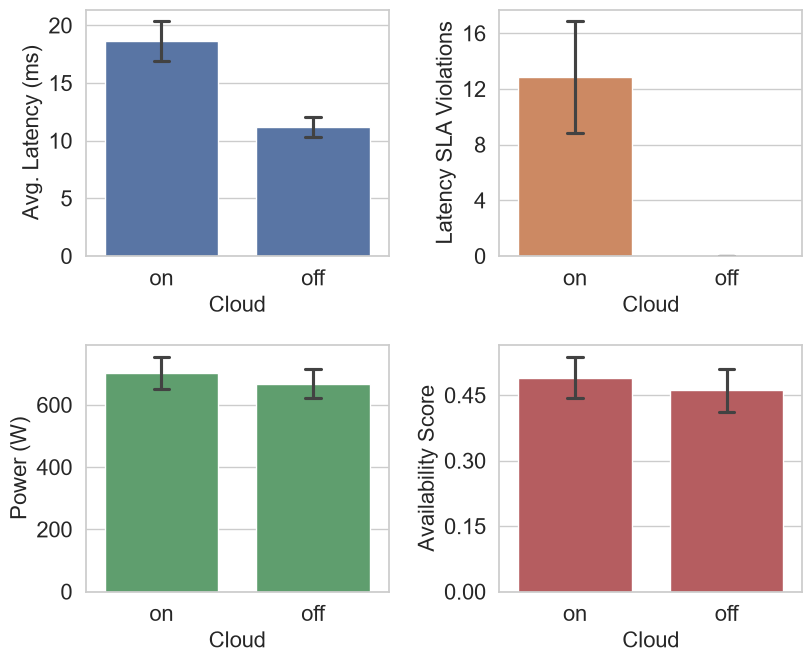

In [54]:
from matplotlib.ticker import MaxNLocator
# list of response variables
y_list = ['Average Latency', 'Latency SLA Violations', 'Power Consumption', 'Availability Score']
y_list_with_units = ['Avg. Latency (ms)', 'Latency SLA Violations', 'Power (W)', 'Availability Score']

# Bar plot by factor
# Defining a color list for the response variables
colors = ['cyan', 'skyblue', 'salmon', 'lightgreen', 'violet', 'gold', 'violet', 'lightgrey', 'orange', 'cyan']

# loop to get all factors
factor_list = ['Algorithm', 'Workload', 'Cloud']
for factor_name in factor_list:
    # Set the figure size
    sns.set(style="whitegrid", font_scale=1.6)
    fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(8.5, 7))  # Adjusted for 2x2 layout

    # Flatten the axs array for easy iteration
    axs = axs.flatten()

    # loop to create plots
    for i in range(len(y_list)):
        y_name = y_list[i]
        bar = sns.barplot(x=factor_name, y=y_name, data=dt_exp_matrix_total,
                    estimator=np.mean, errorbar=('ci', 95), capsize=.1,
                    color=sns.color_palette()[i], width=0.75, ax=axs[i])
        bar.tick_params(axis='both', labelsize=font_size_tics)
        bar.xaxis.label.set_size(font_size_labels - 2)
        bar.yaxis.label.set_size(font_size_labels - 2)


        if y_name in ['Average Latency', 'Latency SLA Violations', 'Power Consumption', 'Availability Score']:
            y_name = y_list_with_units[i]
            axs[i].set(ylabel=y_name)

        # Control the number of y-axis ticks
        axs[i].yaxis.set_major_locator(MaxNLocator(nbins=5))  # Adjust nbins as needed

    plt.tight_layout()
    plt.savefig(f"plots/allalgo_{factor_name}_by_reponsevars_2x2.png", dpi=300)
    plt.savefig(f"plots/allalgo_{factor_name}_by_reponsevars_2x2.pdf", format='pdf')
    plt.show()

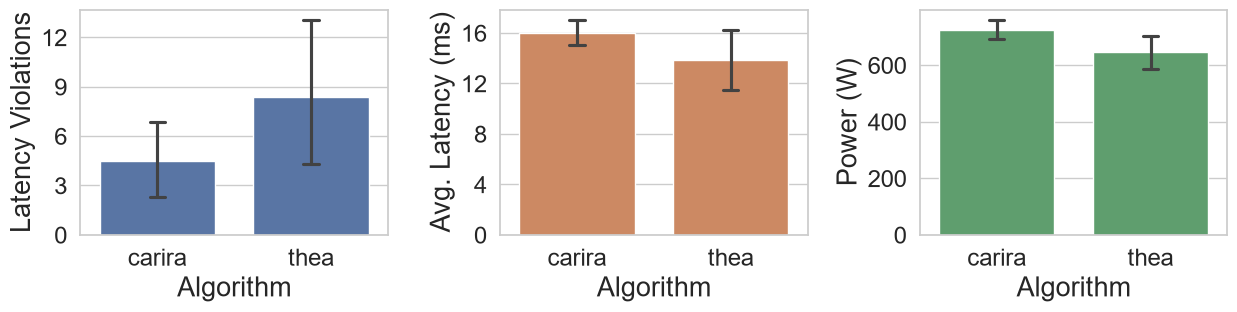

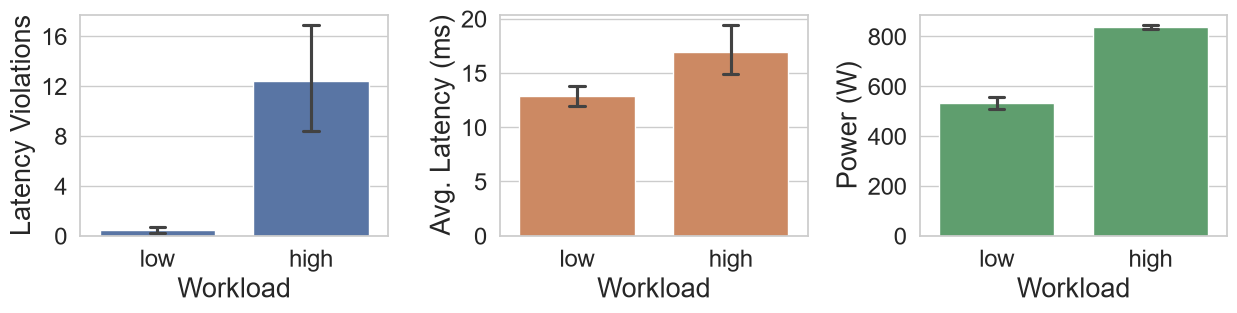

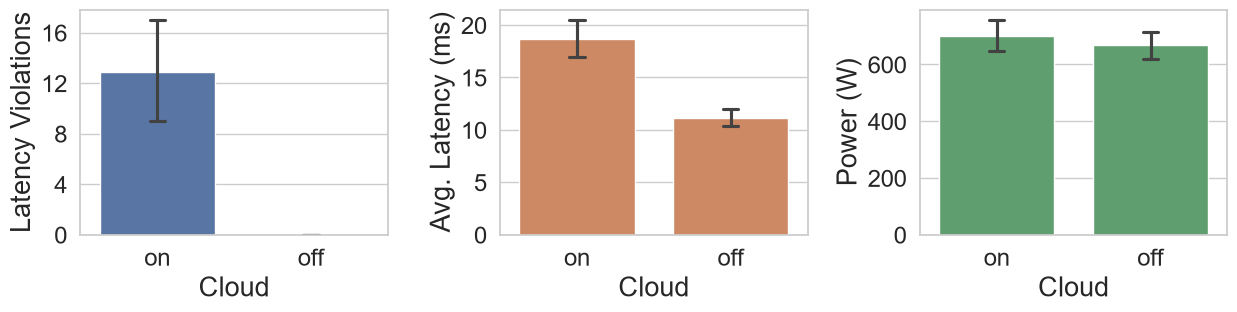

In [55]:
from matplotlib.ticker import MaxNLocator
# list of response variables
y_list = ['Latency SLA Violations', 'Drop SLA Violations', 'Average Latency', 'Power Consumption']
y_list = ['Latency SLA Violations', 'Average Latency', 'Power Consumption']
y_list_with_units = ['Latency Violations', 'Drop Violations', 'Avg. Latency (ms)', 'Power (W)']
y_list_with_units = ['Latency Violations', 'Avg. Latency (ms)', 'Power (W)']
# Bar plot by factor
# Defining a color list for the response variables
colors = ['cyan', 'skyblue', 'salmon', 'lightgreen', 'violet', 'gold', 'violet', 'lightgrey', 'orange', 'cyan']
## loop to get all factors
factor_list = ['Algorithm', 'Workload', 'Cloud']
for factor_name in factor_list:
    ### Set the figure size
    sns.set(style="whitegrid", font_scale=1.6)
    fig, axs = plt.subplots(ncols=len(y_list), figsize=(4.25*len(y_list), 3.5))
    ### loop to create plots
    for i in range(len(y_list)):
        y_name = y_list[i]
        sns.barplot(x=factor_name, y=y_name, data=dt_exp_matrix_total, 
                    estimator=np.mean, errorbar=('ci', 95), capsize=.1, 
                    color=sns.color_palette()[i], width=0.75, ax=axs[i])
        
        #if y_name in ['Latency SLA Violations', 'Drop SLA Violations', 'Average Latency', 'Power Consumption']:
        if y_name in ['Latency SLA Violations', 'Average Latency', 'Power Consumption']:
            y_name = y_list_with_units[i]
            axs[i].set(ylabel=y_name)

        # Control the number of y-axis ticks
        axs[i].yaxis.set_major_locator(MaxNLocator(nbins=5))  # Adjust nbins as needed
    
    plt.tight_layout()
    plt.savefig(f"plots/allalgo_{factor_name}_by_reponsevars.png", dpi=300)
    plt.savefig(f"plots/allalgo_{factor_name}_by_reponsevars.pdf", format='pdf')
    plt.show()

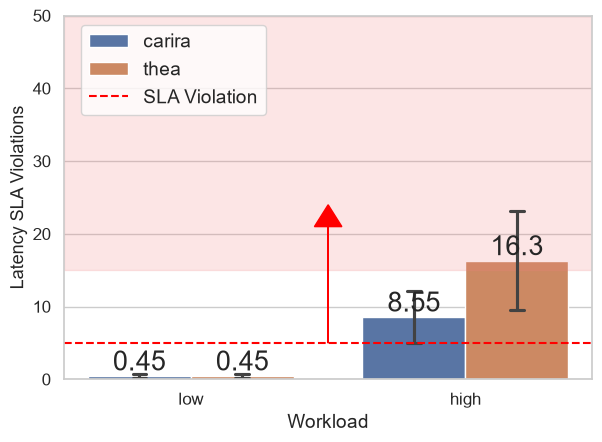

In [56]:
 # Grouped barplot
#sns.set_context(rc={"font.size":14,"axes.titlesize":14,"axes.labelsize":14})
ax = sns.barplot(x="Workload",
            y="Latency SLA Violations",
            hue="Algorithm",
            data=dt_exp_matrix_total, 
            estimator=np.mean, 
            errorbar=('ci', 95), 
            capsize=.1,
            width=0.75,
            )
#ax.bar_label(ax.containers[0], fontsize=20)
plt.axhline(y=5, c='red', linestyle='dashed', label='SLA Violation')
plt.axhspan(15, 50, color='lightcoral', alpha=0.2)
plt.ylim(0, 50)
plt.legend(bbox_to_anchor=(0.4, 1), loc='upper right', fontsize=14)
plt.yticks(fontsize=font_size_tics - 4)
plt.xticks(fontsize=font_size_tics - 4)
plt.ylabel('Latency SLA Violations', fontsize=font_size_labels - 5)
plt.xlabel('Workload', fontsize=font_size_labels - 4)
plt.arrow(0.5, 5, 0, 16, color='red', head_width = 0.1, head_length=3)
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.tight_layout()
plt.savefig(f"plots/allalgo_latency_violations_by_workload.png", dpi=300)
plt.savefig(f"plots/allalgo_latency_violations_by_workload.pdf", format='pdf')
plt.show()

In [57]:
matrix = dt_exp_matrix_total[['Algorithm', 'Cloud', 'Workload', 'Latency SLA Violations', 'Drop SLA Violations', 'Average Latency', 'Power Consumption', 'Availability Score']]

# filtering data
low = matrix.query('Workload == "high"')
#low = matrix.query('Workload == "low"')

print(low)

low_mean = low[['Algorithm', 'Latency SLA Violations', 'Drop SLA Violations', 'Average Latency', 'Power Consumption', 'Availability Score']].groupby(by='Algorithm').mean().round(decimals=2).reset_index()

low_std = low[['Algorithm', 'Latency SLA Violations', 'Drop SLA Violations', 'Average Latency', 'Power Consumption', 'Availability Score']].groupby(by='Algorithm').std().round(decimals=2).reset_index()

display(low_mean)
display(low_std)

   Algorithm Cloud Workload  Latency SLA Violations  Drop SLA Violations  \
20    carira    on     high                    17.0                  0.0   
21    carira    on     high                    15.0                  0.0   
22    carira    on     high                    15.0                  0.0   
23    carira    on     high                    20.0                  0.0   
24    carira    on     high                    15.0                  0.0   
25    carira    on     high                    17.0                  0.0   
26    carira    on     high                    18.0                  0.0   
27    carira    on     high                    18.0                  0.0   
28    carira    on     high                    17.0                  0.0   
29    carira    on     high                    19.0                  0.0   
30    carira   off     high                     0.0                  0.0   
31    carira   off     high                     0.0                  0.0   
32    carira

,Algorithm,Latency SLA Violations,Drop SLA Violations,Average Latency,Power Consumption,Availability Score
0,carira,8.55,0.0,16.47,836.0,0.566667
1,thea,16.30,0.0,17.47,836.0,0.304167


,Algorithm,Latency SLA Violations,Drop SLA Violations,Average Latency,Power Consumption,Availability Score
0,carira,8.85,0.0,4.51,28.73,0.02
1,thea,16.75,0.0,9.25,28.73,0.04


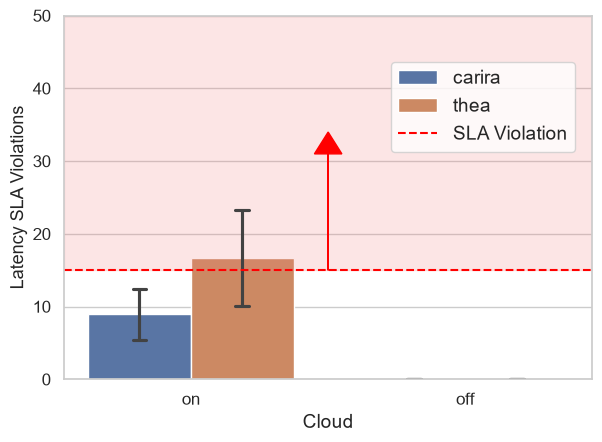

In [58]:
# Grouped barplot
sns.barplot(x="Cloud",
            y="Latency SLA Violations",
            hue="Algorithm",
            data=dt_exp_matrix_total, 
            estimator=np.mean, 
            errorbar=('ci', 95), 
            capsize=.1, 
            width=0.75)
plt.axhline(y=15, c='red', linestyle='dashed', label='SLA Violation')
plt.axhspan(15, 50, color='lightcoral', alpha=0.2)
plt.ylim(0, 50)
plt.legend(bbox_to_anchor=(0.6, 0.90), loc='upper left', fontsize=14)
plt.yticks(fontsize=font_size_tics - 4)
plt.xticks(fontsize=font_size_tics - 4)
plt.ylabel('Latency SLA Violations', fontsize=font_size_labels - 5)
plt.xlabel('Cloud', fontsize=font_size_labels - 4)
plt.arrow(0.5, 15, 0, 16, color='red', head_width = 0.1, head_length=3)
plt.tight_layout()
plt.savefig(f"plots/allalgo_latency_violations_by_cloud.png", dpi=300)
plt.savefig(f"plots/allalgo_latency_violations_by_cloud.pdf", format='pdf')
plt.show()

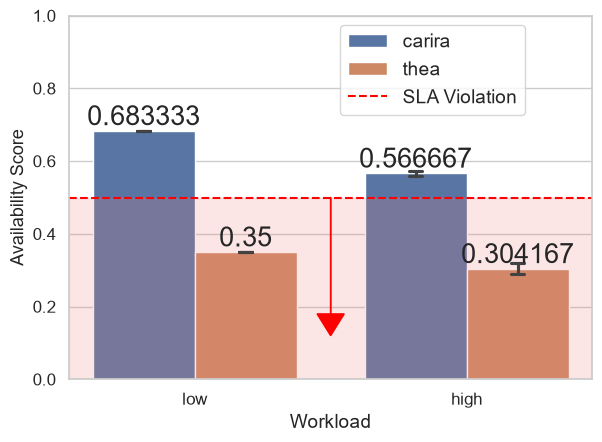

In [59]:
# Grouped barplot
ax = sns.barplot(x="Workload",
            y="Availability Score",
            hue="Algorithm",
            data=dt_exp_matrix_total, 
            estimator=np.mean, 
            errorbar=('ci', 95), 
            capsize=.1, 
            width=0.75)
plt.axhline(y=0.5, c='red', linestyle='dashed', label='SLA Violation')
plt.axhspan(0, 0.5, color='lightcoral', alpha=0.2)
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(0.5, 1), loc='upper left', fontsize=14)
plt.yticks(fontsize=font_size_tics - 4)
plt.xticks(fontsize=font_size_tics - 4)
plt.ylabel('Availability Score', fontsize=font_size_labels - 5)
plt.xlabel('Workload', fontsize=font_size_labels - 4)
plt.arrow(0.5, 0.5, 0, -0.32, color='red', head_width = 0.1, head_length=0.06)
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.tight_layout()
plt.savefig(f"plots/allalgo_availability_score_by_workload.png", dpi=300)
plt.savefig(f"plots/allalgo_availability_score_by_workload.pdf", format='pdf')
plt.show()

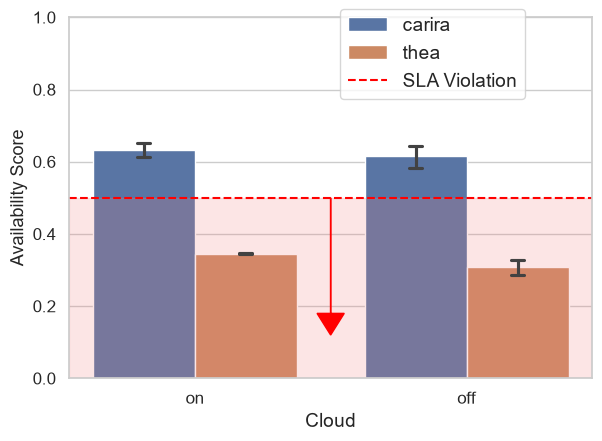

In [60]:
# Grouped barplot
sns.barplot(x="Cloud",
            y="Availability Score",
            hue="Algorithm",
            data=dt_exp_matrix_total,
            estimator=np.mean,
            errorbar=('ci', 95),
            capsize=.1,
            width=0.75)
plt.axhline(y=0.5, c='red', linestyle='dashed', label='SLA Violation')
plt.axhspan(0, 0.5, color='lightcoral', alpha=0.2)
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(0.5, 1.05), loc='upper left', fontsize=14)
plt.yticks(fontsize=font_size_tics - 4)
plt.xticks(fontsize=font_size_tics - 4)
plt.ylabel('Availability Score', fontsize=font_size_labels - 5)
plt.xlabel('Cloud', fontsize=font_size_labels - 4)
plt.arrow(0.5, 0.5, 0, -0.32, color='red', head_width = 0.1, head_length=0.06)
plt.tight_layout()
plt.savefig(f"plots/allalgo_availability_score_by_cloud.png", dpi=300)
plt.savefig(f"plots/allalgo_availability_score_by_cloud.pdf", format='pdf')
plt.show()